# Model pref chosen



# Importing packages

We first import some useful Python packages. pandas is an open source data analysis and manipulation tool built in the Python programming language. Biogeme is a Python package for estimating discrete choice models to explain and predict how people choose among alternatives.

In [1]:
import pandas as pd
import biogeme.database as db
import biogeme.biogeme as bio
from tqdm.notebook import tqdm
from biogeme.expressions import Beta, Variable, log, Derive
from biogeme import models
from biogeme.results_processing import EstimationResults
from biogeme.results_processing import get_pandas_estimated_parameters, html_output

g++ not available, if using conda: `conda install gxx`
c:\Users\chloe\Desktop\3A\Data Science\Modelling Choice Behavior\Biogeme\myvenv\Lib\site-packages\tqdm_joblib\__init__.py:4: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


# Reading and preparing the data

We first import the data into Pandas. We read the data from a text file, where the data are separated by tabs. 

In [2]:
df = pd.read_csv('lpmc19.dat', sep='\t')
df

,trip_id,household_id,person_n,trip_n,travel_mode,purpose,fueltype,faretype,bus_scale,survey_year,...,dur_pt_access,dur_pt_rail,dur_pt_bus,dur_pt_int,pt_interchanges,dur_driving,cost_transit,cost_driving_fuel,cost_driving_ccharge,driving_traffic_percent
0,5,0,1,3,4,3,1,4,1.0,1,...,0.205556,0.000000,0.221111,0.000000,0,0.222222,1.5,0.77,0.0,0.097500
1,16,2,1,2,4,3,1,1,1.0,1,...,0.098611,0.000000,0.058333,0.000000,0,0.058611,1.5,0.16,0.0,0.123223
2,26,7,0,2,1,3,2,1,1.0,1,...,0.068333,0.000000,0.033889,0.000000,0,0.055278,1.5,0.10,0.0,0.105528
3,27,7,1,0,4,4,2,1,1.0,1,...,0.193889,0.516667,0.000000,0.100000,1,0.340833,1.5,2.04,0.0,0.280359
4,52,12,1,2,4,5,2,1,1.0,1,...,0.062500,0.000000,0.491944,0.094722,1,0.355556,3.0,1.19,0.0,0.249219
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,81040,17604,2,0,3,1,1,2,0.0,3,...,0.264444,0.000000,0.353333,0.176667,1,0.288889,0.0,0.85,0.0,0.175000
4996,81059,17606,1,2,3,3,6,1,1.0,3,...,0.100278,0.000000,0.360278,0.000000,0,0.281667,1.5,0.63,0.0,0.384615
4997,81062,17607,0,4,3,5,6,1,1.0,3,...,0.069444,0.000000,0.166389,0.000000,0,0.146111,1.5,0.28,0.0,0.653992
4998,81071,17610,0,0,4,3,2,1,1.0,3,...,0.206111,0.000000,0.400000,0.000000,0,0.259167,1.5,0.88,0.0,0.233655


In [3]:
df['age'].dropna()


0       54
1       41
2       49
3       51
4       56
        ..
4995    17
4996    33
4997    38
4998    33
4999    40
Name: age, Length: 5000, dtype: int64

We then import this database into Biogeme.

In [4]:
database = db.Database('netherlands', df)

We identify the columns that will be used as variables in our model. 

In [5]:
trip_id = Variable('trip_id')
travel_mode = Variable('travel_mode')
purpose = Variable('purpose')
distance = Variable('distance')
dur_walking = Variable('dur_walking')
dur_cycling = Variable('dur_cycling')
dur_pt_access = Variable('dur_pt_access')
dur_pt_rail  = Variable('dur_pt_rail')
dur_pt_bus  = Variable('dur_pt_bus')
dur_pt_int = Variable('dur_pt_int')
dur_driving = Variable('dur_driving')
cost_transit = Variable('cost_transit')
cost_driving_fuel = Variable('cost_driving_fuel')
cost_driving_ccharge = Variable('cost_driving_ccharge')
driving_traffic_percent = Variable('driving_traffic_percent')
age = Variable('age')

In [6]:
database.num_rows()

5000

# Model specification

We can now specify a model that contains 4 ASC

In [7]:
asc_car = Beta('asc_car', 0, None, None, 0)
asc_walk = Beta('asc_walk', 0, None, None, 0)
asc_bike = Beta('asc_bike', 0, None, None, 0)
asc_pt = Beta('asc_pt', 0, None, None, 0)
beta_cost = Beta('beta_cost', 0, None, None, 0)
beta_age = Beta('beta_age', 0, None, None, 0)
beta_time_car = Beta('beta_time_car', 0, None, None, 0)
beta_time_walk = Beta('beta_time_walk', 0, None, None, 0)
beta_time_bike = Beta('beta_time_bike', 0, None, None, 0)
beta_time_pt = Beta('beta_time_pt', 0, None, None, 0)
beta_driving_traffic_percent = Beta('beta_driving_traffic_percent', 0, None, None, 0)
cost_car_euro = database.DefineVariable('cost_car_euro', (cost_driving_fuel + cost_driving_ccharge) * 1.16)
cost_pt_euro = database.DefineVariable('cost_pt_euro', cost_transit * 1.16)
dur_pt_total = database.DefineVariable('dur_pt_total', dur_pt_access + dur_pt_rail + dur_pt_bus + dur_pt_int)

DefineVariable is deprecated; use define_variable instead.
DefineVariable is deprecated; use define_variable instead.
DefineVariable is deprecated; use define_variable instead.


We  write the utility functions:
**We choose walking as the reference**

In [8]:
v_car = asc_car + beta_age * age + beta_cost * cost_car_euro + beta_time_car * log(dur_driving) + beta_driving_traffic_percent * driving_traffic_percent
v_walk = 0 + beta_time_walk * log(dur_walking)
v_bike = asc_bike + beta_age * age + beta_time_bike * log(dur_cycling)
v_pt = asc_pt + beta_age * age + beta_cost * cost_pt_euro + beta_time_pt * log(dur_pt_total)

And we write the choice model:

In [9]:
V = {1: v_walk, 2: v_bike, 3: v_pt, 4: v_car}

Blabla

In [10]:
logprob = models.loglogit(V, None, travel_mode)

We initialize Biogeme with this expression and the database. We call the model 'binary_netherlands'.

In [11]:
biogeme = bio.BIOGEME(database, logprob)
biogeme.model_name = 'model_3'

# Model estimation

Biogeme tries to read a file `__binary_netherlands.iter` containing intermediary results from a previous estimation run. If it does not find it, it triggers a warning that can be ignored.

In [12]:
results_model_3 = biogeme.estimate()

We print some general statistics: 

In [13]:
print(results_model_3.print_general_statistics())

Number of estimated parameters             10
Sample size                                5000
Excluded observations                      0
Init log likelihood                        -6931.472
Final log likelihood                       -4121.26
Likelihood ratio test for the init. model  5620.423
Rho-square for the init. model             0.405
Rho-square-bar for the init. model         0.404
Akaike Information Criterion               8262.52
Bayesian Information Criterion             8327.692
Final gradient norm                        7.4423E-03
Bootstrapping time                         None


We print the estimation results

In [14]:
get_pandas_estimated_parameters(estimation_results=results_model_3)

{'Estimated parameters':                            Name     Value  Robust std err.  Robust t-stat.  \
 0                beta_time_walk -4.191312         0.127085      -32.980397   
 1                      asc_bike -2.575309         0.240312      -10.716544   
 2                      beta_age  0.011037         0.002456        4.494209   
 3                beta_time_bike -2.113964         0.130568      -16.190540   
 4                        asc_pt  1.403749         0.157965        8.886443   
 5                     beta_cost -0.122815         0.014454       -8.497252   
 6                  beta_time_pt -1.676740         0.117366      -14.286453   
 7                       asc_car  1.740406         0.242987        7.162545   
 8                 beta_time_car -1.542058         0.110661      -13.934968   
 9  beta_driving_traffic_percent -2.695288         0.246242      -10.945706   
 
    Robust p-value  
 0    0.000000e+00  
 1    0.000000e+00  
 2    6.982892e-06  
 3    0.000000e+00  


In [15]:
vot_car = Derive(v_car, 'dur_driving') / Derive(v_car, 'cost_car_euro')

In [16]:
vot_pt = Derive(v_pt, 'dur_pt_total') / Derive(v_pt, 'cost_pt_euro')

           VOT_car       VOT_pt
count  5000.000000  5000.000000
mean     92.293907    49.303550
std      92.038258    51.811250
min       7.267086     5.000927
25%      34.557552    21.141684
50%      65.319765    35.006492
75%     118.327951    61.455616
max    1189.507250  1820.337585


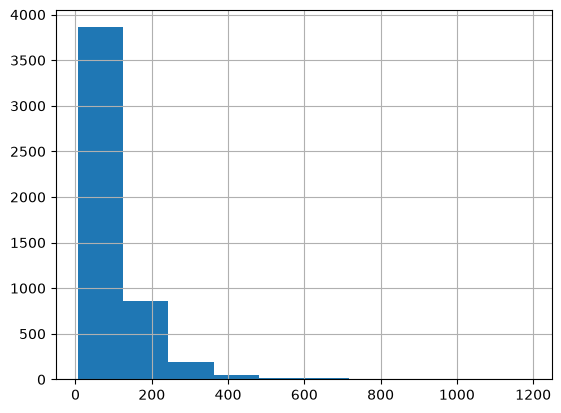

In [17]:
simulate = {'VOT_car': vot_car, 'VOT_pt': vot_pt}
biogeme_sim = bio.BIOGEME(database, simulate)
sim = biogeme_sim.simulate(results_model_3.get_beta_values())
print(sim[['VOT_car', 'VOT_pt']].describe())
_ = sim['VOT_car'].hist()

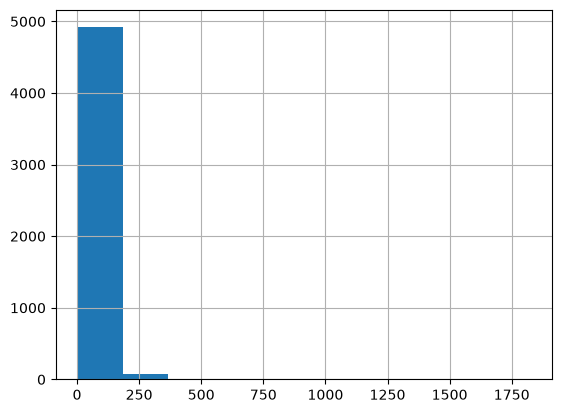

In [18]:
l = sim['VOT_pt'].hist()

---
# Market shares — [2.5 points]

Assume that stratified random sampling was used to produce your sample.
The sample was divided into strata (i.e., groups) and simple random
sampling was used to sample observations in each stratum. We consider the
following strata:

- **S1:** females aged 40 years or younger
- **S2:** females aged 41 years or older
- **S3:** males aged 40 years or younger
- **S4:** males aged 41 years or older

London population estimates in 2015 (Source: ONS):

| | Age ≤ 40 | Age > 40 |
|---|---|---|
| Male | 2'676'249 | 1'633'263 |
| Female | 2'599'058 | 1'765'143 |

## Setup

In [19]:
import numpy as np
import pandas as pd
from scipy import stats

import biogeme.database as db
import biogeme.biogeme as bio
from biogeme import models
from biogeme.expressions import Beta, Variable
from biogeme.results_processing import EstimationResults

# Load the LPMC sample
data = pd.read_csv("lpmc19.dat", sep="\t")
data.head()

,trip_id,household_id,person_n,trip_n,travel_mode,purpose,fueltype,faretype,bus_scale,survey_year,...,dur_pt_access,dur_pt_rail,dur_pt_bus,dur_pt_int,pt_interchanges,dur_driving,cost_transit,cost_driving_fuel,cost_driving_ccharge,driving_traffic_percent
0,5,0,1,3,4,3,1,4,1.0,1,...,0.205556,0.000000,0.221111,0.000000,0,0.222222,1.5,0.77,0.0,0.097500
1,16,2,1,2,4,3,1,1,1.0,1,...,0.098611,0.000000,0.058333,0.000000,0,0.058611,1.5,0.16,0.0,0.123223
2,26,7,0,2,1,3,2,1,1.0,1,...,0.068333,0.000000,0.033889,0.000000,0,0.055278,1.5,0.10,0.0,0.105528
3,27,7,1,0,4,4,2,1,1.0,1,...,0.193889,0.516667,0.000000,0.100000,1,0.340833,1.5,2.04,0.0,0.280359
4,52,12,1,2,4,5,2,1,1.0,1,...,0.062500,0.000000,0.491944,0.094722,1,0.355556,3.0,1.19,0.0,0.249219


**1.** Report the size and weight of each stratum in your sample.
**[1 point]**

In [20]:
N3 = 2676249
N4 = 1633263
N1 = 2599058
N2 = 1765143

#Population
N = N1 + N2 + N3 + N4

#Table of Ng/N
table_ng_n = [[N3/N, N4/N], [N1/N, N2/N]] 

table = pd.DataFrame(table_ng_n, columns=["Age =< 40", "Age > 40"], index=["Male", "Female"])
print(f'Table of Ng/N:')
print(table)

Table of Ng/N:
        Age =< 40  Age > 40
Male     0.308547  0.188300
Female   0.299648  0.203505


In [21]:
S3 = len(data.loc[(data['age'] <= 40) & (data['female'] == 0)])
S4 = len(data.loc[(data['age'] > 40) & (data['female'] == 0)])
S1 = len(data.loc[(data['age'] <= 40) & (data['female'] == 1)])
S2 = len(data.loc[(data['age'] > 40) & (data['female'] == 1)])

#Population of the sample
S = S1 + S2 + S3 + S4

#Table of Sg/S
table_sg_s = [[S3/S, S4/S], [S1/S, S2/S]]

table = pd.DataFrame(table_sg_s, columns=["Age =< 40", "Age > 40"], index=["Male", "Female"])
print(f'Table of Sg/S:')
print(table)

Table of Sg/S:
        Age =< 40  Age > 40
Male       0.2502    0.2278
Female     0.2830    0.2390


In [22]:
#Table of weights Ng/N * S/Sg
table_weights_strata = [[table_ng_n[0][0]*(1/table_sg_s[0][0]),table_ng_n[0][1]*(1/table_sg_s[0][1])], [table_ng_n[1][0]*(1/table_sg_s[1][0]),table_ng_n[1][1]*(1/table_sg_s[1][1])]]

table_weights = pd.DataFrame(table_weights_strata, columns=["Age =< 40", "Age > 40"], index=["Male", "Female"])
print(f'Table of weights:')
print(table_weights)
print(f'Size of stratum Male and under 40:', S3)
print(f'Size of stratum Male and over 40:', S4)
print(f'Size of stratum Female and under 40:', S1)
print(f'Size of stratum Female and over 40:', S2)

Table of weights:
        Age =< 40  Age > 40
Male     1.233202  0.826604
Female   1.058826  0.851485
Size of stratum Male and under 40: 1251
Size of stratum Male and over 40: 1139
Size of stratum Female and under 40: 1415
Size of stratum Female and over 40: 1195


In [23]:
# Your answer here: stratum sizes and weights (S1-S4)

**2.** Using $\text{Model}_{\text{pref}}$ and the weights of your strata,
compute the predicted market share of each mode and their confidence
intervals. Do the obtained results match your expectations? **[1 point]**

In [24]:
#Création colonne avec weights pour chaque individu, la somme de cette colonne doit etre egale à la somme du nombre d'observation du sample
df['Weight'] = np.select(
    [(df['female'] == 0) & (df['age'] <= 40),
     (df['female'] == 0) & (df['age'] >  40),
     (df['female'] == 1) & (df['age'] <= 40),
     (df['female'] == 1) & (df['age'] >  40)],
    [table_weights_strata[0][0], table_weights_strata[0][1],
     table_weights_strata[1][0], table_weights_strata[1][1]])

database = db.Database('with weights', df)

In [25]:
#Verification
sum_weights = df['Weight'].sum()
print(sum_weights, len(df))

5000.0 5000


In [26]:
#Ici on ajoute Weight comme variable à simuler
Weight = Variable('Weight')

av = {1: 1, 2: 1, 3: 1, 4: 1}

simulate = {
    'Weight': Weight,
    'walk':  models.logit(V, av, 1),
    'cycle': models.logit(V, av, 2),
    'pt':    models.logit(V, av, 3),
    'drive': models.logit(V, av, 4)
}

#Prédit pour chaque individu la proba qu'il/elle choisse l'alternative
biosim = bio.BIOGEME(database, simulate)
simulated_values = biosim.simulate(results_model_3.get_beta_values())

In [27]:
simulated_values

,Weight,walk,cycle,pt,drive
0,0.826604,NaN,NaN,NaN,NaN
1,0.826604,NaN,NaN,NaN,NaN
2,0.851485,NaN,NaN,NaN,NaN
3,0.826604,NaN,NaN,NaN,NaN
4,0.851485,NaN,NaN,NaN,NaN
...,...,...,...,...,...
4995,1.233202,NaN,NaN,NaN,NaN
4996,1.058826,NaN,NaN,NaN,NaN
4997,1.058826,NaN,NaN,NaN,NaN
4998,1.058826,NaN,NaN,NaN,NaN


In [28]:
#The market shares are calculated using the weighted mean of the individual probabilities
simulated_values['Weighted walk'] = (
    simulated_values['Weight'] * 
    simulated_values['walk']
)
simulated_values['Weighted cycle'] = (
    simulated_values['Weight'] * 
    simulated_values['cycle']
)
simulated_values['Weighted pt'] = (
    simulated_values['Weight'] * 
    simulated_values['pt']
)
simulated_values['Weighted drive'] = (
    simulated_values['Weight'] * 
    simulated_values['drive']
)

In [29]:
market_share_walk = simulated_values['Weighted walk'].mean()
print(f'Market share for walk: {100*market_share_walk:.1f}%')

market_share_cycle = simulated_values['Weighted cycle'].mean()
print(f'Market share for cycle: {100*market_share_cycle:.1f}%')

market_share_pt = simulated_values['Weighted pt'].mean()
print(f'Market share for pt: {100*market_share_pt:.1f}%')

market_share_drive = simulated_values['Weighted drive'].mean()
print(f'Market share for drive: {100*market_share_drive:.1f}%')

Market share for walk: nan%
Market share for cycle: nan%
Market share for pt: nan%
Market share for drive: nan%


**We calculate now the confidence intervals of the market shares**

In [30]:
results_bootstrapping = biogeme.estimate(run_bootstrap=True)
estimated_parameters = get_pandas_estimated_parameters(estimation_results=results_bootstrapping)
display(estimated_parameters)

Bootstraps:   0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

Bootstraps:   0%|          | 0/100 [00:47<?, ?it/s]


{'Estimated parameters':                            Name     Value  Bootstrap std err.  \
 0                beta_time_walk -4.191312            0.131648   
 1                      asc_bike -2.575309            0.244778   
 2                      beta_age  0.011037            0.002714   
 3                beta_time_bike -2.113964            0.117514   
 4                        asc_pt  1.403749            0.173721   
 5                     beta_cost -0.122815            0.016071   
 6                  beta_time_pt -1.676740            0.116723   
 7                       asc_car  1.740406            0.280054   
 8                 beta_time_car -1.542058            0.113529   
 9  beta_driving_traffic_percent -2.695288            0.244705   
 
    Bootstrap t-stat.  Bootstrap p-value  
 0         -31.837350       0.000000e+00  
 1         -10.521002       0.000000e+00  
 2           4.067470       4.752642e-05  
 3         -17.989035       0.000000e+00  
 4           8.080499       6.661

We obtain a sample of values for the parameters we can use to calculate the 90% confidence intervals on the simulated quantities.

In [31]:
betas = biogeme.free_betas_names
b = results_bootstrapping.get_betas_for_sensitivity_analysis(betas, size = 100)

left, right = biosim.confidence_intervals(b, interval_size=0.9)

100%|██████████| 100/100 [00:00<00:00, 364.53it/s]


In [32]:
left['Weighted walk'] = (
    left['Weight'] * 
    left['walk']
)
left['Weighted cycle'] = (
    left['Weight'] * 
    left['cycle']
)
left['Weighted pt'] = (
    left['Weight'] * 
    left['pt']
)
left['Weighted drive'] = (
    left['Weight'] * 
    left['drive']
)

right['Weighted walk'] = (
    right['Weight'] * 
    right['walk']
)
right['Weighted cycle'] = (
    right['Weight'] * 
    right['cycle']
)
right['Weighted pt'] = (
    right['Weight'] * 
    right['pt']
)
right['Weighted drive'] = (
    right['Weight'] * 
    right['drive']
)

In [33]:
left_market_share_walk = left['Weighted walk'].mean()
left_market_share_cycle = left['Weighted cycle'].mean()
left_market_share_pt = left['Weighted pt'].mean()
left_market_share_drive = left['Weighted drive'].mean()

right_market_share_walk = right['Weighted walk'].mean()
right_market_share_cycle = right['Weighted cycle'].mean()
right_market_share_pt = right['Weighted pt'].mean()
right_market_share_drive = right['Weighted drive'].mean()

In [34]:
print(
    f'Market share for walk: {100*market_share_walk:.1f}% '
    f'CI: ['
    f'{100*left_market_share_walk:.1f}%-'
    f'{100*right_market_share_walk:.1f}%'
    f']'
)
print(
    f'Market share for cycle: {100*market_share_cycle:.1f}% '
    f'CI: ['
    f'{100*left_market_share_cycle:.1f}%-'
    f'{100*right_market_share_cycle:.1f}%'
    f']'
)
print(
    f'Market share for pt: {100*market_share_pt:.1f}% '
    f'CI: ['
    f'{100*left_market_share_pt:.1f}%-'
    f'{100*right_market_share_pt:.1f}%'
    f']'
)
print(
    f'Market share for drive: {100*market_share_drive:.1f}% '
    f'CI: ['
    f'{100*left_market_share_drive:.1f}%-'
    f'{100*right_market_share_drive:.1f}%'
    f']'
)

Market share for walk: nan% CI: [nan%-nan%]
Market share for cycle: nan% CI: [nan%-nan%]
Market share for pt: nan% CI: [nan%-nan%]
Market share for drive: nan% CI: [nan%-nan%]


In [35]:
# Your answer here: weighted predicted market shares + confidence intervals

**3.** Compare the market shares predicted by $\text{Model}_{\text{pref}}$
with the weighted market shares computed using the actual choices.
**[0.5 point]**

In [36]:
# Your answer here

---
# Forecasting — [6 points]

Consider the following scenarios:
- **(i)** an increase of car cost by 15%;
- **(ii)** a decrease of public transport cost by 15%.

## **1.** Report the market shares predicted by $\text{Model}_{\text{pref}}$
for each scenario. Do they match your expectations? Compare the predicted
market shares with the original market shares. **[1 point]**

### Scenario 1 : increase of car cost by 15%

In [37]:
v_car_scenario_1 = asc_car + beta_age * age + 1.15 * beta_cost * cost_car_euro + beta_time_car * log(dur_driving) + beta_driving_traffic_percent * driving_traffic_percent

V = {1: v_walk, 2: v_bike, 3: v_pt, 4: v_car_scenario_1}

av = {1: 1, 2: 1, 3: 1, 4: 1} ## as described in the biogeme documentation

prob_walk_scenario_1 = models.logit(V, av, 1)
prob_bike_scenario_1 = models.logit(V, av, 2)
prob_pt_scenario_1   = models.logit(V, av, 3)
prob_car_scenario_1  = models.logit(V, av, 4)

We then add the variables to simulate the scenario

In [38]:
simulate_scenario_1 = {
    'Weight': Weight,
    'Prob. pt': prob_pt_scenario_1,
    'Prob. car': prob_car_scenario_1,
    'Prob. walk': prob_walk_scenario_1,
    'Prob. bike': prob_bike_scenario_1
}

biosim_scenario_1 = bio.BIOGEME(database, simulate_scenario_1)
simulated_scenario_1 = biosim_scenario_1.simulate(results_model_3.get_beta_values())
simulated_scenario_1


,Weight,Prob. pt,Prob. car,Prob. walk,Prob. bike
0,0.826604,NaN,NaN,NaN,NaN
1,0.826604,NaN,NaN,NaN,NaN
2,0.851485,NaN,NaN,NaN,NaN
3,0.826604,NaN,NaN,NaN,NaN
4,0.851485,NaN,NaN,NaN,NaN
...,...,...,...,...,...
4995,1.233202,NaN,NaN,NaN,NaN
4996,1.058826,NaN,NaN,NaN,NaN
4997,1.058826,NaN,NaN,NaN,NaN
4998,1.058826,NaN,NaN,NaN,NaN


And then calculate the market shares of our first scenario

In [39]:
left_scenario_1, right_scenario_1 = biosim_scenario_1.confidence_intervals(b, 0.9)

simulated_scenario_1['Weighted pt'] = (
    simulated_scenario_1['Weight'] * 
    simulated_scenario_1['Prob. pt']
)
simulated_scenario_1['Weighted car'] = (
    simulated_scenario_1['Weight'] * 
    simulated_scenario_1['Prob. car']
)
simulated_scenario_1['Weighted walk'] = (
    simulated_scenario_1['Weight'] * 
    simulated_scenario_1['Prob. walk']
)
simulated_scenario_1['Weighted bike'] = (
    simulated_scenario_1['Weight'] * 
    simulated_scenario_1['Prob. bike']
)

100%|██████████| 100/100 [00:00<00:00, 437.52it/s]


In [40]:
market_share_pt_scenario_1 = simulated_scenario_1['Weighted pt'].mean()
market_share_car_scenario_1 = simulated_scenario_1['Weighted car'].mean()
market_share_walk_scenario_1 = simulated_scenario_1['Weighted walk'].mean()
market_share_bike_scenario_1 = simulated_scenario_1['Weighted bike'].mean()

Finally, we calculate the intervals of these market shares.

In [41]:
right_scenario_1['Weighted pt'] = (
    right_scenario_1['Weight'] * 
    right_scenario_1['Prob. pt']
)
right_scenario_1['Weighted car'] = (
    right_scenario_1['Weight'] * 
    right_scenario_1['Prob. car']
)
right_scenario_1['Weighted walk'] = (
    right_scenario_1['Weight'] * 
    right_scenario_1['Prob. walk']
)
right_scenario_1['Weighted bike'] = (
    right_scenario_1['Weight'] * 
    right_scenario_1['Prob. bike']
)

left_scenario_1['Weighted pt'] = (
    left_scenario_1['Weight'] * 
    left_scenario_1['Prob. pt']
)
left_scenario_1['Weighted car'] = (
    left_scenario_1['Weight'] * 
    left_scenario_1['Prob. car']
)
left_scenario_1['Weighted walk'] = (
    left_scenario_1['Weight'] * 
    left_scenario_1['Prob. walk']
)
left_scenario_1['Weighted bike'] = (
    left_scenario_1['Weight'] * 
    left_scenario_1['Prob. bike']
)

In [42]:
left_market_share_pt_scenario_1 = left_scenario_1['Weighted pt'].mean()
left_market_share_car_scenario_1 = left_scenario_1['Weighted car'].mean()
left_market_share_walk_scenario_1 = left_scenario_1['Weighted walk'].mean()
left_market_share_bike_scenario_1 = left_scenario_1['Weighted bike'].mean()

right_market_share_pt_scenario_1 = right_scenario_1['Weighted pt'].mean()
right_market_share_car_scenario_1 = right_scenario_1['Weighted car'].mean()
right_market_share_walk_scenario_1 = right_scenario_1['Weighted walk'].mean()
right_market_share_bike_scenario_1 = right_scenario_1['Weighted bike'].mean()

In [43]:
print(
    f'Market share for walk: {100*market_share_walk_scenario_1:.1f}% '
    f'CI: ['
    f'{100*left_market_share_walk_scenario_1:.1f}%-'
    f'{100*right_market_share_walk_scenario_1:.1f}%'
    f']'
)
print(
    f'Market share for cycle: {100*market_share_bike_scenario_1:.1f}% '
    f'CI: ['
    f'{100*left_market_share_bike_scenario_1:.1f}%-'
    f'{100*right_market_share_bike_scenario_1:.1f}%'
    f']'
)
print(
    f'Market share for pt: {100*market_share_pt_scenario_1:.1f}% '
    f'CI: ['
    f'{100*left_market_share_pt_scenario_1:.1f}%-'
    f'{100*right_market_share_pt_scenario_1:.1f}%'
    f']'
)
print(
    f'Market share for drive: {100*market_share_car_scenario_1:.1f}% '
    f'CI: ['
    f'{100*left_market_share_car_scenario_1:.1f}%-'
    f'{100*right_market_share_car_scenario_1:.1f}%'
    f']'
)

Market share for walk: nan% CI: [nan%-nan%]
Market share for cycle: nan% CI: [nan%-nan%]
Market share for pt: nan% CI: [nan%-nan%]
Market share for drive: nan% CI: [nan%-nan%]


### Scenario 2 : decrease of public transport cost by 15%

In [44]:
v_pt_scenario_2 = asc_pt + beta_age * age + beta_cost * cost_pt_euro * 0.85 + beta_time_pt * log(dur_pt_total)

V = {1: v_walk, 2: v_bike, 3: v_pt_scenario_2, 4: v_car}

av = {1: 1, 2: 1, 3: 1, 4: 1} ## as described in the biogeme documentation

prob_walk_scenario_2 = models.logit(V, av, 1)
prob_bike_scenario_2 = models.logit(V, av, 2)
prob_pt_scenario_2   = models.logit(V, av, 3)
prob_car_scenario_2  = models.logit(V, av, 4)

We then add the variables to simulate the scenario

In [45]:
simulate_scenario_2 = {
    'Weight': Weight,
    'Prob. pt': prob_pt_scenario_2,
    'Prob. car': prob_car_scenario_2,
    'Prob. walk': prob_walk_scenario_2,
    'Prob. bike': prob_bike_scenario_2
}

biosim_scenario_2 = bio.BIOGEME(database, simulate_scenario_2)
simulated_scenario_2 = biosim_scenario_2.simulate(results_model_3.get_beta_values())
simulated_scenario_2


,Weight,Prob. pt,Prob. car,Prob. walk,Prob. bike
0,0.826604,NaN,NaN,NaN,NaN
1,0.826604,NaN,NaN,NaN,NaN
2,0.851485,NaN,NaN,NaN,NaN
3,0.826604,NaN,NaN,NaN,NaN
4,0.851485,NaN,NaN,NaN,NaN
...,...,...,...,...,...
4995,1.233202,NaN,NaN,NaN,NaN
4996,1.058826,NaN,NaN,NaN,NaN
4997,1.058826,NaN,NaN,NaN,NaN
4998,1.058826,NaN,NaN,NaN,NaN


And then calculate the market shares of our second scenario

In [46]:
left_scenario_2, right_scenario_2 = biosim_scenario_2.confidence_intervals(b, 0.9)

simulated_scenario_2['Weighted pt'] = (
    simulated_scenario_2['Weight'] * 
    simulated_scenario_2['Prob. pt']
)
simulated_scenario_2['Weighted car'] = (
    simulated_scenario_2['Weight'] * 
    simulated_scenario_2['Prob. car']
)
simulated_scenario_2['Weighted walk'] = (
    simulated_scenario_2['Weight'] * 
    simulated_scenario_2['Prob. walk']
)
simulated_scenario_2['Weighted bike'] = (
    simulated_scenario_2['Weight'] * 
    simulated_scenario_2['Prob. bike']
)

100%|██████████| 100/100 [00:00<00:00, 479.83it/s]


In [47]:
market_share_pt_scenario_2 = simulated_scenario_2['Weighted pt'].mean()
market_share_car_scenario_2 = simulated_scenario_2['Weighted car'].mean()
market_share_walk_scenario_2 = simulated_scenario_2['Weighted walk'].mean()
market_share_bike_scenario_2 = simulated_scenario_2['Weighted bike'].mean()

Finally, we calculate the intervals of these market shares.

In [48]:
right_scenario_2['Weighted pt'] = (
    right_scenario_2['Weight'] * 
    right_scenario_2['Prob. pt']
)
right_scenario_2['Weighted car'] = (
    right_scenario_2['Weight'] * 
    right_scenario_2['Prob. car']
)
right_scenario_2['Weighted walk'] = (
    right_scenario_2['Weight'] * 
    right_scenario_2['Prob. walk']
)
right_scenario_2['Weighted bike'] = (
    right_scenario_2['Weight'] * 
    right_scenario_2['Prob. bike']
)

left_scenario_2['Weighted pt'] = (
    left_scenario_2['Weight'] * 
    left_scenario_2['Prob. pt']
)
left_scenario_2['Weighted car'] = (
    left_scenario_2['Weight'] * 
    left_scenario_2['Prob. car']
)
left_scenario_2['Weighted walk'] = (
    left_scenario_2['Weight'] * 
    left_scenario_2['Prob. walk']
)
left_scenario_2['Weighted bike'] = (
    left_scenario_2['Weight'] * 
    left_scenario_2['Prob. bike']
)

In [49]:
left_market_share_pt_scenario_2 = left_scenario_2['Weighted pt'].mean()
left_market_share_car_scenario_2 = left_scenario_2['Weighted car'].mean()
left_market_share_walk_scenario_2 = left_scenario_2['Weighted walk'].mean()
left_market_share_bike_scenario_2 = left_scenario_2['Weighted bike'].mean()

right_market_share_pt_scenario_2 = right_scenario_2['Weighted pt'].mean()
right_market_share_car_scenario_2 = right_scenario_2['Weighted car'].mean()
right_market_share_walk_scenario_2 = right_scenario_2['Weighted walk'].mean()
right_market_share_bike_scenario_2 = right_scenario_2['Weighted bike'].mean()

In [50]:
print(
    f'Market share for walk: {100*market_share_walk_scenario_2:.1f}% '
    f'CI: ['
    f'{100*left_market_share_walk_scenario_2:.1f}%-'
    f'{100*right_market_share_walk_scenario_2:.1f}%'
    f']'
)
print(
    f'Market share for cycle: {100*market_share_bike_scenario_2:.1f}% '
    f'CI: ['
    f'{100*left_market_share_bike_scenario_2:.1f}%-'
    f'{100*right_market_share_bike_scenario_2:.1f}%'
    f']'
)
print(
    f'Market share for pt: {100*market_share_pt_scenario_2:.1f}% '
    f'CI: ['
    f'{100*left_market_share_pt_scenario_2:.1f}%-'
    f'{100*right_market_share_pt_scenario_2:.1f}%'
    f']'
)
print(
    f'Market share for drive: {100*market_share_car_scenario_2:.1f}% '
    f'CI: ['
    f'{100*left_market_share_car_scenario_2:.1f}%-'
    f'{100*right_market_share_car_scenario_2:.1f}%'
    f']'
)

Market share for walk: nan% CI: [nan%-nan%]
Market share for cycle: nan% CI: [nan%-nan%]
Market share for pt: nan% CI: [nan%-nan%]
Market share for drive: nan% CI: [nan%-nan%]


### **2.** Which scenario is the most effective policy if the goal is to decrease the share of car? 
Explain why. **[0.5 point]**

Plotting the two scenarios : 

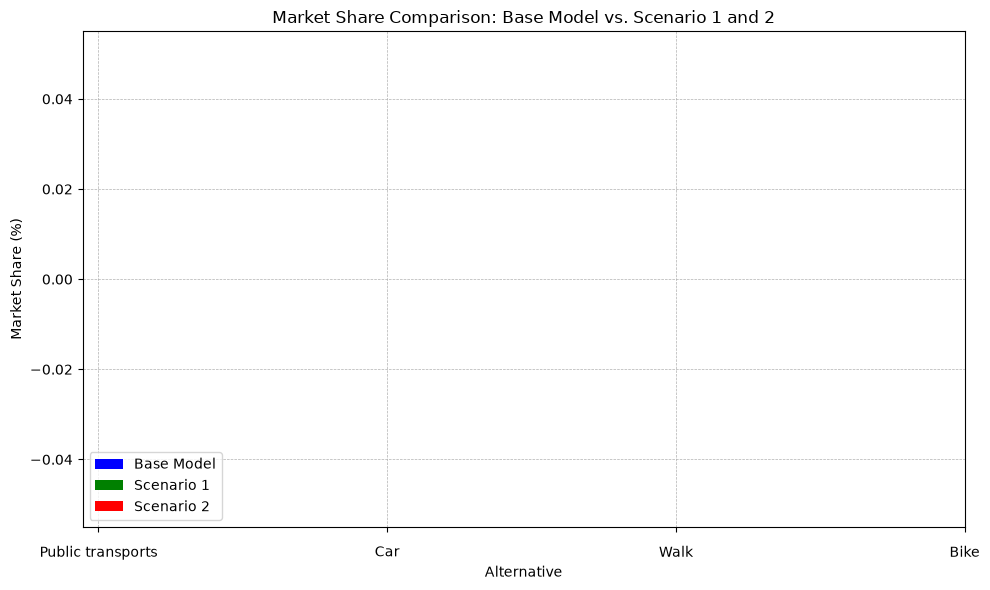

In [51]:
import matplotlib.pyplot as plt
import numpy as np

alternatives = ['Public transports', 'Car', 'Walk', 'Bike']

# We create a list for every scenario 
market_share_base = [
    market_share_pt, 
    market_share_drive,
    market_share_walk,
    market_share_cycle,
]

intervals_base = np.array([
    [left_market_share_pt, right_market_share_pt],
    [left_market_share_drive, right_market_share_drive],
    [left_market_share_walk, right_market_share_walk],
    [left_market_share_cycle, right_market_share_cycle],
])

# Scenario 1
market_share_scenario_1 = [
    market_share_pt_scenario_1,
    market_share_car_scenario_1,
    market_share_walk_scenario_1,
    market_share_bike_scenario_1,
]

intervals_scenario_1 = np.array([
    [left_market_share_pt_scenario_1, right_market_share_pt_scenario_1],
    [left_market_share_car_scenario_1, right_market_share_car_scenario_1],
    [left_market_share_walk_scenario_1, right_market_share_walk_scenario_1],
    [left_market_share_bike_scenario_1, right_market_share_bike_scenario_1],
])

# Scenario 2
market_share_scenario_2 = [
    market_share_pt_scenario_2,
    market_share_car_scenario_2,
    market_share_walk_scenario_2,
    market_share_bike_scenario_2,
]

intervals_scenario_2 = np.array([
    [left_market_share_pt_scenario_2, right_market_share_pt_scenario_2],
    [left_market_share_car_scenario_2, right_market_share_car_scenario_2],
    [left_market_share_walk_scenario_2, right_market_share_walk_scenario_2],
    [left_market_share_bike_scenario_2, right_market_share_bike_scenario_2],
])

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(alternatives))
width = 0.25

# Base model
ax.bar(x - width, market_share_base, width,
       yerr=[np.array(market_share_base) - intervals_base[:, 0],
             intervals_base[:, 1] - np.array(market_share_base)],
       capsize=5, color='blue', label='Base Model')

# Scenario 1
bars_scenario_1 = ax.bar(x, market_share_scenario_1, width,
                         yerr=[np.array(market_share_scenario_1) - intervals_scenario_1[:, 0],
                               intervals_scenario_1[:, 1] - np.array(market_share_scenario_1)],
                         capsize=5, color='green', label='Scenario 1')

# Scenario 2
bars_scenario_2 = ax.bar(x + width, market_share_scenario_2, width,
                         yerr=[np.array(market_share_scenario_2) - intervals_scenario_2[:, 0],
                               intervals_scenario_2[:, 1] - np.array(market_share_scenario_2)],
                         capsize=5, color='red', label='Scenario 2')

# Add labels, title, legend
ax.set_xlabel('Alternative')
ax.set_ylabel('Market Share (%)')
ax.set_xticks(x)
ax.set_xticklabels(alternatives)
ax.tick_params(axis='x', which='major', bottom=True, labelbottom=True, pad=10)
ax.set_title('Market Share Comparison: Base Model vs. Scenario 1 and 2')
ax.legend()

ax.grid(True, linestyle='--', linewidth=0.5)

# Show the plot
plt.tight_layout()
plt.show()


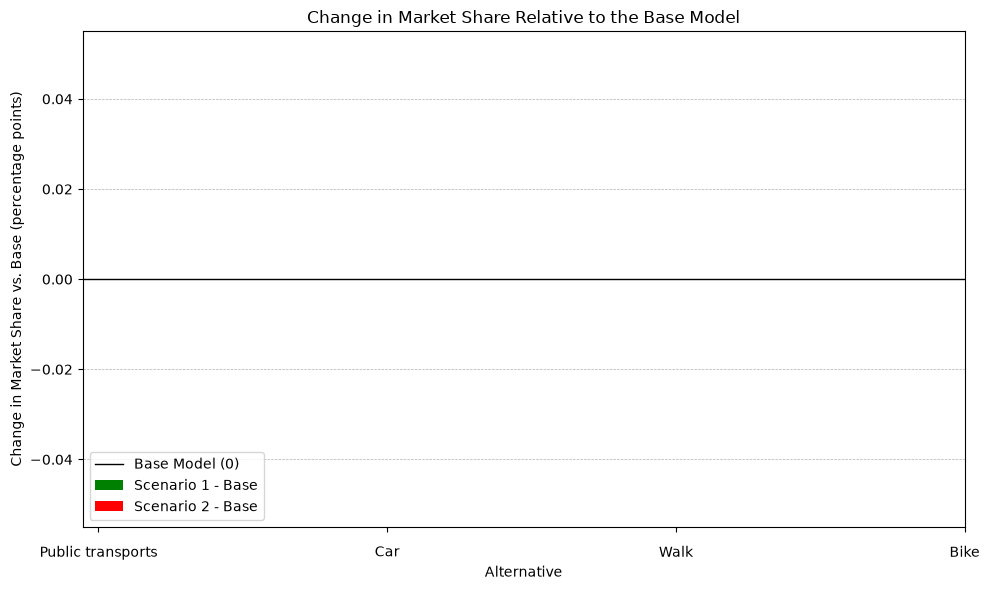

In [52]:
import matplotlib.pyplot as plt
import numpy as np

alternatives = ['Public transports', 'Car', 'Walk', 'Bike']
x = np.arange(len(alternatives))
width = 0.35

# Convert everything to arrays for easy math
base = np.array(market_share_base, dtype=float)
s1 = np.array(market_share_scenario_1, dtype=float)
s2 = np.array(market_share_scenario_2, dtype=float)

# Distances from each share down to its left bound and up to its right bound
base_low = base - intervals_base[:, 0]
base_up = intervals_base[:, 1] - base
s1_low = s1 - intervals_scenario_1[:, 0]
s1_up = intervals_scenario_1[:, 1] - s1
s2_low = s2 - intervals_scenario_2[:, 0]
s2_up = intervals_scenario_2[:, 1] - s2

# Differences from the base model
diff_1 = s1 - base
diff_2 = s2 - base

# Uncertainty of a difference: combine the two errors (assumes the models are independent)
err_1 = [np.sqrt(s1_low**2 + base_low**2), np.sqrt(s1_up**2 + base_up**2)]
err_2 = [np.sqrt(s2_low**2 + base_low**2), np.sqrt(s2_up**2 + base_up**2)]

fig, ax = plt.subplots(figsize=(10, 6))

bars_1 = ax.bar(x - width / 2, diff_1, width, yerr=err_1, capsize=5,
                color='green', label='Scenario 1 - Base')
bars_2 = ax.bar(x + width / 2, diff_2, width, yerr=err_2, capsize=5,
                color='red', label='Scenario 2 - Base')

# Zero line = the base model
ax.axhline(0, color='black', linewidth=1, label='Base Model (0)')

# Write the value on each bar, with a sign
ax.bar_label(bars_1, fmt='%+.1f', padding=3)
ax.bar_label(bars_2, fmt='%+.1f', padding=3)

ax.set_xlabel('Alternative')
ax.set_ylabel('Change in Market Share vs. Base (percentage points)')
ax.set_title('Change in Market Share Relative to the Base Model')
ax.set_xticks(x)
ax.set_xticklabels(alternatives)
ax.tick_params(axis='x', pad=10)
ax.legend()

ax.grid(True, axis='y', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

As seen with our two results, the third model seems pretty stable. 

#### Since our model is pretty stable, we are trying another scenario to compare it with

In [53]:
Since our model

SyntaxError: invalid syntax (1363037165.py, line 1)

## **3.** Calculate the total public transportation revenue in each scenario.
Which scenario reports the highest total revenue? Explain why. Is it
higher than the total revenue obtained without any of the policies? Can
you explain why? **[1.5 points]**

In [ ]:
# Your answer here: total public transport revenue per scenario

## **4.** Calculate the average value of time for car and public transportation. 
Comment on the obtained results. **[1 point]**

In [ ]:
# Your answer here: average value of time (car, public transport)

## **5.** Compute the direct and cross aggregate elasticities of car cost and public transport cost. 
Comment on the obtained results. Report the normalization factors. **[2 points]**

In [ ]:
# Your answer here: direct and cross aggregate elasticities + normalization factors